# 0. Set up

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from scipy.stats import norm, skew

sns.set_theme(context='notebook', style='ticks', palette='bright')
sns.color_palette()

[(0.00784313725490196, 0.24313725490196078, 1.0),
 (1.0, 0.48627450980392156, 0.0),
 (0.10196078431372549, 0.788235294117647, 0.2196078431372549),
 (0.9098039215686274, 0.0, 0.043137254901960784),
 (0.5450980392156862, 0.16862745098039217, 0.8862745098039215),
 (0.6235294117647059, 0.2823529411764706, 0.0),
 (0.9450980392156862, 0.2980392156862745, 0.7568627450980392),
 (0.6392156862745098, 0.6392156862745098, 0.6392156862745098),
 (1.0, 0.7686274509803922, 0.0),
 (0.0, 0.8431372549019608, 1.0)]

In [36]:
# Load datasets
PATH = Path(Path.cwd().parent / 'data')
train = pd.read_csv(PATH / 'train.csv')
test = pd.read_csv(PATH / 'test.csv')

# Save IDs for later
train_ID = train.Id
test_ID = test.Id

# Drop IDs
train = train.drop('Id', axis=1)
test = test.drop('Id', axis=1)

print(f'Train Size: {train.shape}')
print(f'Test Size: {test.shape}')

Train Size: (1460, 80)
Test Size: (1459, 79)


# 1. Data Processing
## 1.1 Outliers

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

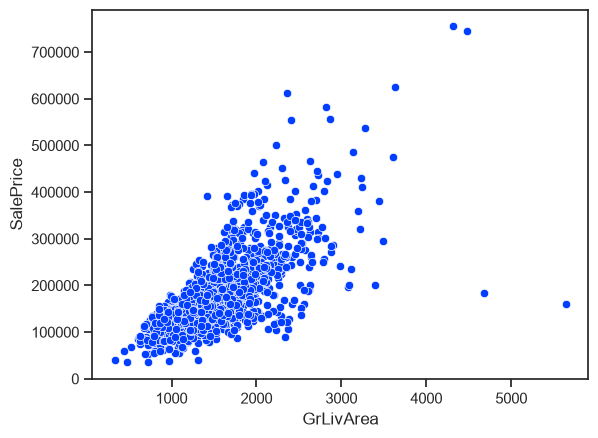

In [37]:
sns.scatterplot(train, x='GrLivArea', y='SalePrice')

In [38]:
# drop outliers
train = train.drop(train[(train.GrLivArea > 4000) & (train.SalePrice < 300000)].index)
train.shape

(1458, 80)

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

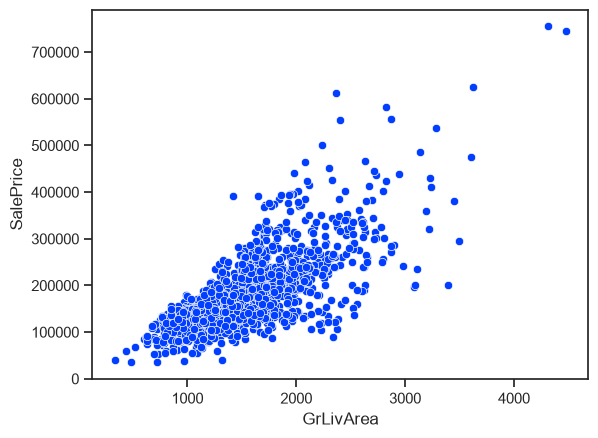

In [39]:
sns.scatterplot(train, x='GrLivArea', y='SalePrice')

## 1.2 Target Variable

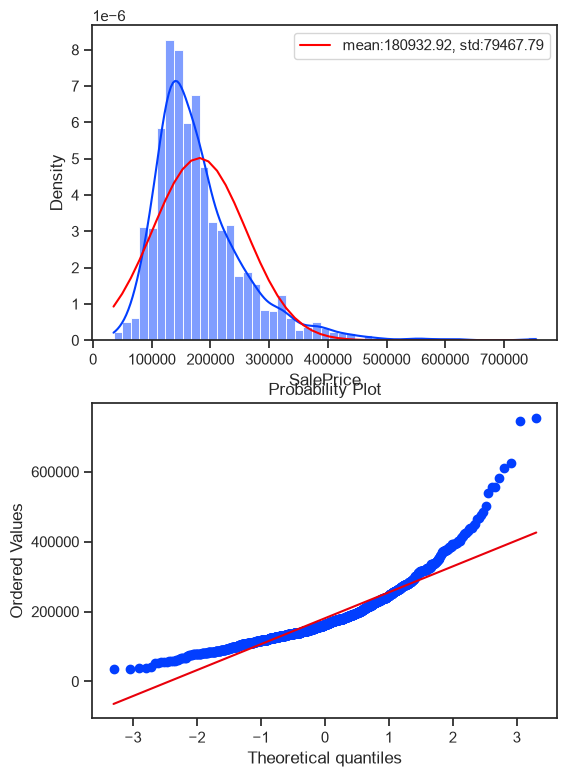

In [63]:
# Distribution of the target variable
fig, ax = plt.subplots(2, 1, figsize=(6, 9))

sns.histplot(train, x='SalePrice', stat='density', kde=True, ax=ax[0])

mu, std = norm.fit(train.SalePrice)
x = np.linspace(min(train.SalePrice), max(train.SalePrice))
pdf = norm.pdf(x, mu, std)

ax[0].plot(x, pdf, color='red', label=f'mean:{mu:.2f}, std:{std:.2f}')
ax[0].legend()

# probability plot
stats.probplot(train.SalePrice, plot=ax[1]);



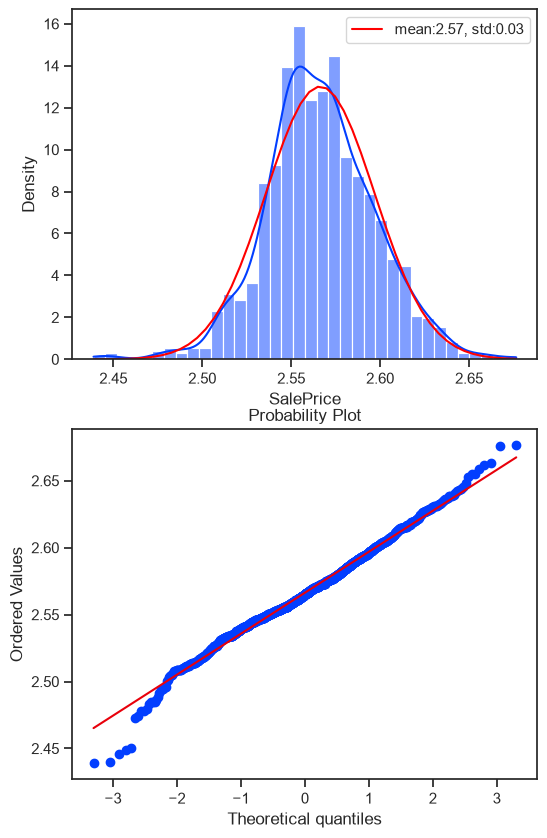

In [76]:
# Normalize SalePrice by log transforming it
train['SalePrice'] = np.log1p(train.SalePrice)

# Redraw the normal distribution plot
fig, ax = plt.subplots(2, 1, figsize=(6, 10))

sns.histplot(train, x='SalePrice', stat='density', kde=True, ax=ax[0])

mu, std = norm.fit(train.SalePrice)
x = np.linspace(min(train.SalePrice), max(train.SalePrice))
pdf = norm.pdf(x, mu, std)

ax[0].plot(x, pdf, color='red', label=f'mean:{mu:.2f}, std:{std:.2f}')
ax[0].legend()

# Probability plot
stats.probplot(train.SalePrice, plot=ax[1]);



## 1.3 Features Engineering

In [ ]:
# Concat Train and Test to one DF
all_data = pd.concat([train, test]).reset_index(drop=True)
all_data = all_data.drop('SalePrice', axis=1)
all_data.shape

(2917, 79)

### 1.3.1 Missing Data

In [75]:
all_data_na = pd.concat((all_data.isna().sum(), all_data.isna().sum()/all_data.isna().count()), axis=1, keys=('Total', 'Percentage'))

all_data_na = all_data_na.sort_values(by='Total', ascending=False)
all_data_na.head(35)

,Total,Percentage
PoolQC,2908,0.996915
MiscFeature,2812,0.964004
Alley,2719,0.932122
Fence,2346,0.804251
MasVnrType,1766,0.605417
FireplaceQu,1420,0.486802
LotFrontage,486,0.166610
GarageYrBlt,159,0.054508
GarageFinish,159,0.054508
GarageQual,159,0.054508


<Axes: xlabel='None', ylabel='Percentage'>

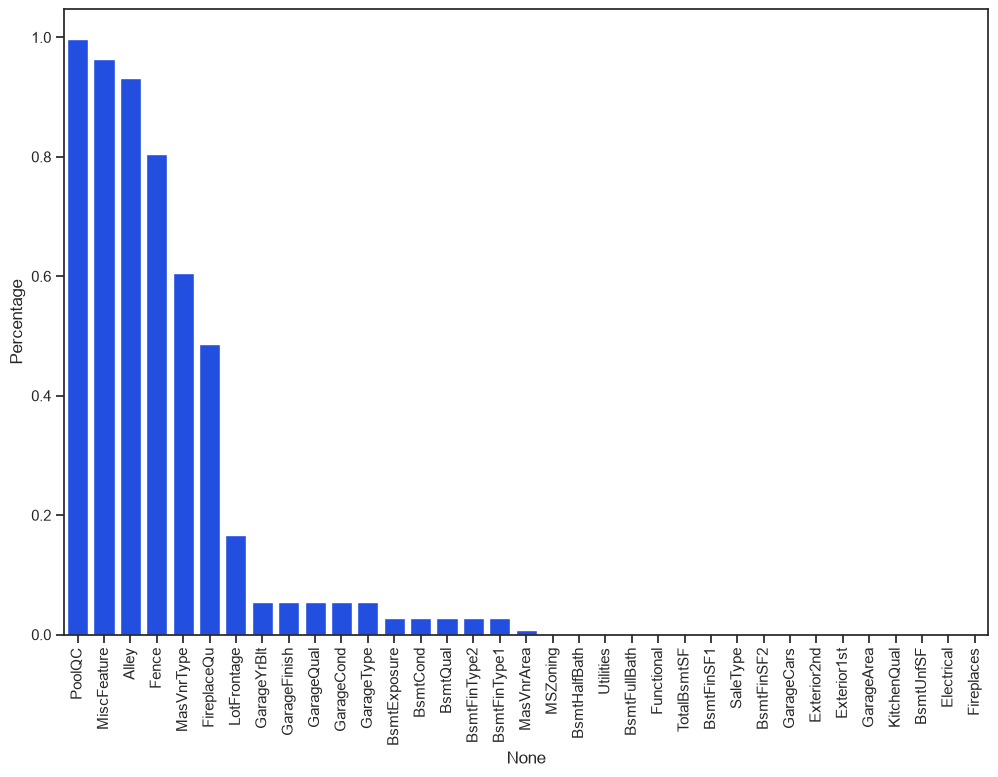

In [79]:
fig, ax = plt.subplots(figsize=(10, 7))
plt.xticks(rotation=90)
plt.tight_layout();
sns.barplot(x=all_data_na.index[:35], y=all_data_na.Percentage[:35])

### 1.3.2 Correlation

<Axes: >

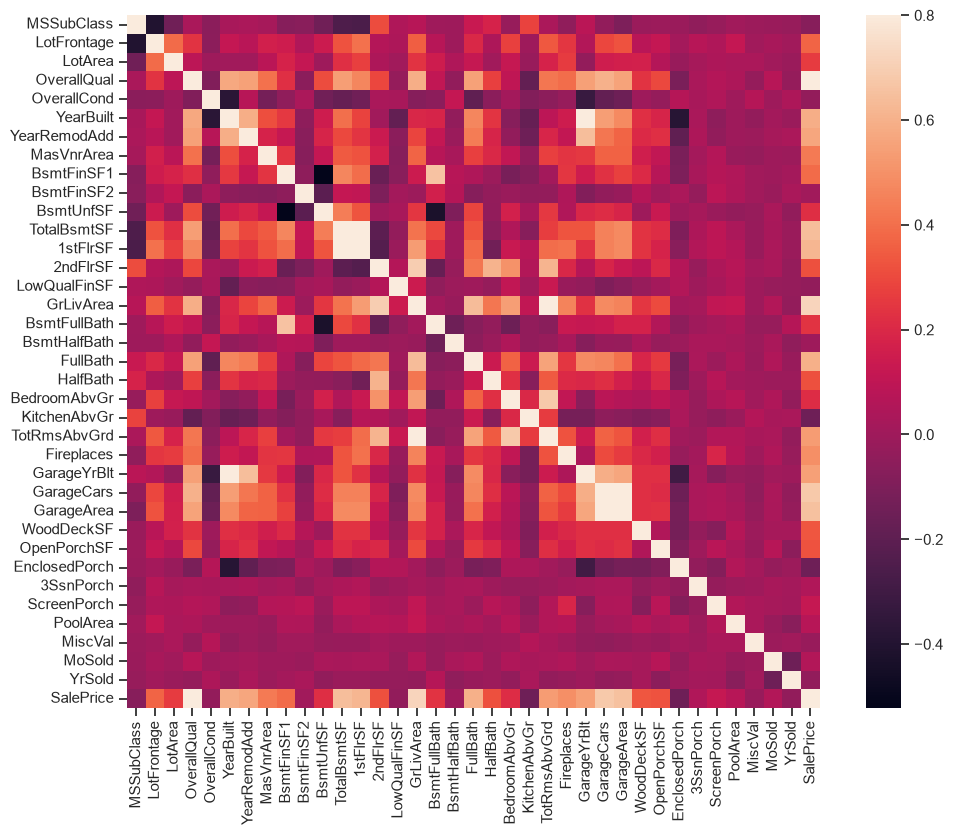

In [82]:
corrmat = train.corr(numeric_only=True)
plt.subplots(figsize=(12, 9))
sns.heatmap(corrmat, vmax=.8, square=True)

### 1.3.3 Null Data Imputation


In [83]:
# PoolQC NA means no pool according to data_description.txt
all_data['PoolQC'] = all_data['PoolQC'].fillna('None')

In [84]:
# MiscFeature NA means None according to data_description.txt
all_data['MiscFeature'] = all_data['MiscFeature'].fillna('None')

In [85]:
# Alley NA means None according to data_description.txt
all_data['Alley'] = all_data['Alley'].fillna('None')

In [86]:
# Fence NA means None according to data_description.txt
all_data['Fence'] = all_data['Fence'].fillna('None')

In [89]:
# MasVnrType NA means None according to data_description.txt
all_data['MasVnrType'] = all_data['MasVnrType'].fillna('None')

In [90]:
# FireplaceQu NA means None according to data_description.txt
all_data['FireplaceQu'] = all_data['FireplaceQu'].fillna('None')

In [94]:
# LotFrontage probably is similar to other properties' in the same neighborhood
# Take mean of the lot frontages in the neighborhood and assign them
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

In [98]:
# All GarageX features have same amount of NA values
# GarageType NA means no garage according to data_description.txt
# Thus, fill NA's according to this info
all_data['GarageArea'] = all_data['GarageArea'].fillna(0)
all_data['GarageCars'] = all_data['GarageCars'].fillna(0)
all_data['GarageCond'] = all_data['GarageCond'].fillna('None')
all_data['GarageFinish'] = all_data['GarageFinish'].fillna('None')
all_data['GarageQual'] = all_data['GarageQual'].fillna('None')
all_data['GarageType'] = all_data['GarageType'].fillna('None')
all_data['GarageYrBlt'] = all_data['GarageYrBlt'].fillna(0)


In [99]:
all_data_na.head(35).index

Index(['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu',
       'LotFrontage', 'GarageYrBlt', 'GarageFinish', 'GarageQual',
       'GarageCond', 'GarageType', 'BsmtExposure', 'BsmtCond', 'BsmtQual',
       'BsmtFinType2', 'BsmtFinType1', 'MasVnrArea', 'MSZoning',
       'BsmtHalfBath', 'Utilities', 'BsmtFullBath', 'Functional',
       'TotalBsmtSF', 'BsmtFinSF1', 'SaleType', 'BsmtFinSF2', 'GarageCars',
       'Exterior2nd', 'Exterior1st', 'GarageArea', 'KitchenQual', 'BsmtUnfSF',
       'Electrical', 'Fireplaces'],
      dtype='str')

In [131]:
# All BsmtX features probably mean no Basement
basement_cat = ['BsmtExposure', 'BsmtCond', 'BsmtQual', 'BsmtFinType2', 'BsmtFinType1']
basement_num = ['MasVnrArea', 'TotalBsmtSF', 'BsmtFinSF1', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmtHalfBath', 'BsmtFullBath']

for feat in basement_cat:
    all_data[feat] = all_data[feat].fillna('None')
for feat in basement_num:
    all_data[feat] = all_data[feat].fillna(0)

In [ ]:
# MSZoning, fillna with the most common zone there
all_data['MSZoning'] = all_data['MSZoning'].fillna(all_data['MSZoning'].mode()[0])

In [ ]:
# Utilities 
# For this categorical feature all records are "AllPub", except for one "NoSeWa" and 2 NA . 
# Since the house with 'NoSewa' is in the training set, this feature won't help in predictive modelling. 
# We can then safely remove it.
all_data = all_data.drop('Utilities', axis=1)

In [127]:
# Functional NA probably means typical
all_data['Functional'] = all_data['Functional'].fillna('Typ')

In [ ]:
# Electrical NA probably means standard breaker
all_data['Electrical'] = all_data['Electrical'].fillna('SBrkr')

In [134]:
# Erterior2nd, KitchenQual, SaleType, Exterior1st all have 1 NA
# We are good to probably replace it with the most common
features = ['Exterior2nd', 'KitchenQual', 'SaleType', 'Exterior1st']
for feat in features:
    all_data[feat] = all_data[feat].fillna(all_data[feat].mode()[0])

In [136]:
(all_data.isna().sum()).sum() == 0

np.True_

### 1.3.4 Category Encoding